# Milestone #1 Task #4: Image Preprocessing
Telecom-2A Classification and Fraud Detection for Sensitive Documents

**What this notebook does:**
1. Downloads the IDNet dataset from Kaggle
2. Samples it down to a manageable size
3. Generates a synthetic "fake" class using blur + noise
4. Preprocesses everything: grayscale + resize (Task #4 — your actual job)
5. Saves the result so Tasks #5–7 (EDA, HOG, LBP) can load it directly


## Step 0: Install dependencies

In [ ]:
!pip install -q kaggle opencv-python-headless scikit-image numpy matplotlib

## Step 1: Upload your Kaggle API key
select the `kaggle.json` you downloaded from Kaggle.

In [ ]:
from google.colab import files
import os

uploaded = files.upload()  # select kaggle.json when the file picker pops up

os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json
print("Kaggle credentials set up.")

Saving kaggle.json to kaggle.json
Kaggle credentials set up.


## Step 2: Download the IDNet dataset


In [ ]:
DATASET_SLUG = "chitreshkr/idnet-identity-document-analysis"

!kaggle datasets download -d {DATASET_SLUG} -p /content/data/raw

print("Download complete. Contents:")
!ls -la /content/data/raw

Dataset URL: https://www.kaggle.com/datasets/chitreshkr/idnet-identity-document-analysis
License(s): other
100% 45.6G/45.6G [08:51<00:00, 92.1MB/s]

Download complete. Contents:
total 47763652
drwxr-xr-x 2 root root        4096 Sep 22 03:42 .
drwxr-xr-x 3 root root        4096 Sep 22 03:42 ..
-rw-r--r-- 1 root root 48909961477 Sep 30  2024 idnet-identity-document-analysis.zip


In [ ]:
DATASET_SLUG = "chitreshkr/idnet-identity-document-analysis"

!kaggle datasets download -d {DATASET_SLUG} -p /content/data/raw

print("Download complete. Contents:")

!ls -la /content/data/raw

Dataset URL: https://www.kaggle.com/datasets/chitreshkr/idnet-identity-document-analysis
License(s): other
100% 45.6G/45.6G [10:53<00:00, 74.9MB/s]

Download complete. Contents:
total 47763652
drwxr-xr-x 2 root root        4096 Sep 22 18:00 .
drwxr-xr-x 3 root root        4096 Sep 22 18:00 ..
-rw-r--r-- 1 root root 48909961477 Sep 30  2024 idnet-identity-document-analysis.zip


In [ ]:
!ls -lh /content/data/raw

total 46G
-rw-r--r-- 1 root root 46G Sep 30  2024 idnet-identity-document-analysis.zip


In [ ]:
import zipfile

zip_path = "/content/data/raw/idnet-identity-document-analysis.zip"

outer = zipfile.ZipFile(zip_path, "r")

print("Outer ZIP opened successfully.")
print("Entries:")
for name in outer.namelist():
    print(name)

Outer ZIP opened successfully.
Entries:
files-archive


In [ ]:
files_archive_file = outer.open("files-archive", "r")

inner_zip = zipfile.ZipFile(files_archive_file, "r")

print("First files inside files-archive:")
for name in inner_zip.namelist()[:20]:
    print(name)

First files inside files-archive:
GRC.zip
WV.zip
RUS.zip


In [ ]:
grc_file = inner_zip.open("GRC.zip", "r")

grc_zip = zipfile.ZipFile(grc_file, "r")

print("First 30 entries inside GRC.zip:")
for name in grc_zip.namelist()[:30]:
    print(name)

First 30 entries inside GRC.zip:
GRC/
GRC/fraud3_face_replacement/
GRC/fraud3_face_replacement/generated.photos_v3_0651904.png
GRC/fraud3_face_replacement/generated.photos_v3_0676531_0924751_0704350.png
GRC/fraud3_face_replacement/generated.photos_v3_0805623.png
GRC/fraud3_face_replacement/generated.photos_v3_0662567_0001952_0953720.png
GRC/fraud3_face_replacement/generated.photos_v3_0863857.png
GRC/fraud3_face_replacement/generated.photos_v3_0428002.png
GRC/fraud3_face_replacement/generated.photos_v3_0510611.png
GRC/fraud3_face_replacement/generated.photos_v3_0338168.png
GRC/fraud3_face_replacement/generated.photos_v3_0050078.png
GRC/fraud3_face_replacement/generated.photos_v3_0778303.png
GRC/fraud3_face_replacement/generated.photos_v3_0212176.png
GRC/fraud3_face_replacement/generated.photos_v3_0357334.png
GRC/fraud3_face_replacement/generated.photos_v3_0332109.png
GRC/fraud3_face_replacement/generated.photos_v3_0837852.png
GRC/fraud3_face_replacement/generated.photos_v3_0714982.png
G

In [ ]:
import os

sample_dir = "/content/data/raw/idnet_sample"
os.makedirs(sample_dir, exist_ok=True)

image_files = [
    name for name in grc_zip.namelist()
    if name.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Total images in GRC:", len(image_files))
print("First 5:", image_files[:5])

Total images in GRC: 41852
First 5: ['GRC/fraud3_face_replacement/generated.photos_v3_0651904.png', 'GRC/fraud3_face_replacement/generated.photos_v3_0676531_0924751_0704350.png', 'GRC/fraud3_face_replacement/generated.photos_v3_0805623.png', 'GRC/fraud3_face_replacement/generated.photos_v3_0662567_0001952_0953720.png', 'GRC/fraud3_face_replacement/generated.photos_v3_0863857.png']


In [ ]:
import os

sample_dir = "/content/data/raw/idnet_sample"
os.makedirs(sample_dir, exist_ok=True)

SAMPLE_SIZE = 600

for i, name in enumerate(image_files[:SAMPLE_SIZE]):
    output_path = os.path.join(sample_dir, f"{i:04d}.png")

    with grc_zip.open(name) as source:
        with open(output_path, "wb") as target:
            target.write(source.read())

    if (i + 1) % 50 == 0:
        print(f"Saved {i + 1}/{SAMPLE_SIZE}")

print("Done!")
print("Sample location:", sample_dir)

Saved 50/600
Saved 100/600
Saved 150/600
Saved 200/600
Saved 250/600
Saved 300/600
Saved 350/600
Saved 400/600
Saved 450/600
Saved 500/600
Saved 550/600
Saved 600/600
Done!
Sample location: /content/data/raw/idnet_sample


In [ ]:
!du -sh /content/data/raw/idnet_sample
!ls /content/data/raw/idnet_sample | head

125M	/content/data/raw/idnet_sample
0000.png
0001.png
0002.png
0003.png
0004.png
0005.png
0006.png
0007.png
0008.png
0009.png


In [ ]:
from collections import Counter

folders = []

for name in grc_zip.namelist():
    if name.lower().endswith((".jpg", ".jpeg", ".png")):
        parts = name.split("/")
        if len(parts) >= 2:
            folders.append(parts[1])

print("Image categories:")
for folder, count in Counter(folders).most_common():
    print(folder, ":", count)

Image categories:
fraud3_face_replacement : 5979
fraud4_combined : 5979
fraud5_inpaint_and_rewrite : 5979
fraud2_face_morphing : 5979
positive : 5979
fraud1_copy_and_move : 5979
fraud6_crop_and_replace : 5978


In [ ]:
positive_files = [
    name for name in grc_zip.namelist()
    if "/positive/" in name.lower()
    and name.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Positive images:", len(positive_files))
print("First 5:", positive_files[:5])

Positive images: 5979
First 5: ['GRC/positive/generated.photos_v3_0651904.png', 'GRC/positive/generated.photos_v3_0676531_0924751_0704350.png', 'GRC/positive/generated.photos_v3_0805623.png', 'GRC/positive/generated.photos_v3_0662567_0001952_0953720.png', 'GRC/positive/generated.photos_v3_0863857.png']


In [ ]:
import os

positive_sample_dir = "/content/data/raw/positive_sample"
os.makedirs(positive_sample_dir, exist_ok=True)

SAMPLE_SIZE = 600

for i, name in enumerate(positive_files[:SAMPLE_SIZE]):
    output_path = os.path.join(positive_sample_dir, f"{i:04d}.png")

    with grc_zip.open(name) as source:
        with open(output_path, "wb") as target:
            target.write(source.read())

    if (i + 1) % 50 == 0:
        print(f"Saved {i + 1}/{SAMPLE_SIZE}")

print("Done!")
print("Location:", positive_sample_dir)

Saved 50/600
Saved 100/600
Saved 150/600
Saved 200/600
Saved 250/600
Saved 300/600
Saved 350/600
Saved 400/600
Saved 450/600
Saved 500/600
Saved 550/600
Saved 600/600
Done!
Location: /content/data/raw/positive_sample


In [ ]:
!du -sh /content/data/raw/positive_sample
!ls /content/data/raw/positive_sample | head

125M	/content/data/raw/positive_sample
0000.png
0001.png
0002.png
0003.png
0004.png
0005.png
0006.png
0007.png
0008.png
0009.png


In [ ]:
import cv2
import os
import glob

input_dir = "/content/data/raw/positive_sample"
output_dir = "/content/data/processed/positive"

os.makedirs(output_dir, exist_ok=True)

TARGET_SIZE = (256, 256)

image_files = glob.glob(os.path.join(input_dir, "*.png"))

for i, path in enumerate(image_files):
    img = cv2.imread(path)

    if img is None:
        continue

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    resized = cv2.resize(gray, TARGET_SIZE)

    output_path = os.path.join(output_dir, os.path.basename(path))
    cv2.imwrite(output_path, resized)

print("Done!")
print("Processed:", len(image_files))
print("Saved to:", output_dir)

Done!
Processed: 600
Saved to: /content/data/processed/positive


In [ ]:
import zipfile

zip_path = "/content/data/raw/idnet-identity-document-analysis.zip"

with zipfile.ZipFile(zip_path, 'r') as z:
    all_names = z.namelist()
    image_names = [n for n in all_names if n.lower().endswith(('.jpg', '.jpeg', '.png'))]
    print(f"Total entries in zip: {len(all_names)}")
    print(f"Image files found: {len(image_names)}")
    print("First few:", image_names[:5])

Total entries in zip: 1
Image files found: 0
First few: []


In [ ]:
with zipfile.ZipFile(zip_path, 'r') as z:
    for info in z.infolist():
        print(info.filename, info.file_size)

files-archive 48912872785


In [ ]:
with zipfile.ZipFile(zip_path, 'r') as z:
    info = z.getinfo("files-archive")
    print("Compression type:", info.compress_type)  # 0 = stored (good, means seekable), 8 = deflated (harder)

Compression type: 8


In [ ]:
import os

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extract("files-archive", "/content/data/raw")

print("Extracted. New file size:")
!ls -la /content/data/raw

OSError: [Errno 28] No space left on device

In [ ]:
import os
partial_path = "/content/data/raw/files-archive"
if os.path.exists(partial_path):
    os.remove(partial_path)
    print("Removed partial extract.")
!df -h /content

Removed partial extract.
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   66G   42G  62% /


In [ ]:
!pip install -q stream-unzip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.3/271.3 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 50.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 707.4/707.4 kB 26.4 MB/s eta 0:00:00


In [ ]:
import zipfile
import os
from stream_unzip import stream_unzip

zip_path = "/content/data/raw/idnet-identity-document-analysis.zip"

# Folder where we will save the sample
extract_dir = "/content/data/raw/idnet_sample"
os.makedirs(extract_dir, exist_ok=True)

SAMPLE_SIZE = 600
saved_count = 0

outer_zip = zipfile.ZipFile(zip_path, 'r')

def zipped_chunks():
    with outer_zip.open("files-archive") as f:
        while True:
            chunk = f.read(1024 * 1024)
            if not chunk:
                break
            yield chunk

# Look at the files inside files-archive
count = 0

for file_name, file_size, unzipped_chunks in stream_unzip(zipped_chunks()):

    name_str = file_name.decode('utf-8', errors='ignore')

    print("Found:", name_str)

    # We only need to inspect the first 20 files
    for chunk in unzipped_chunks:
        pass

    count += 1

    if count >= 20:
        break

outer_zip.close()

NotStreamUnzippable: b'GRC.zip'

In [ ]:
import zipfile

zip_path = "/content/data/raw/idnet-identity-document-analysis.zip"

outer = zipfile.ZipFile(zip_path)

print("Files inside outer ZIP:")
for name in outer.namelist():
    print(name)

Files inside outer ZIP:
files-archive


In [ ]:
info = outer.getinfo("files-archive")

print("Compressed size:", info.compress_size)
print("Uncompressed size:", info.file_size)

Compressed size: 48909961237
Uncompressed size: 48912872785


In [ ]:
# Show the first few entries inside files-archive
with outer.open("files-archive") as f:
    data = f.read(10 * 1024 * 1024)  # only read first 10 MB

print(data[:100])

b'PK\x03\x04-\x00\x08\x00\x00\x00\x85\x10>Y\x00\x00\x00\x00\xff\xff\xff\xff\xff\xff\xff\xff\x07\x00\x14\x00GRC.zip\x01\x00\x10\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00PK\x03\x04\n\x00\x00\x00\x00\x00\x12;;Y\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x04\x00\x1c\x00GRC/UT\t\x00\x03\xb4]\xf6f'


In [ ]:
import zipfile
import io

with outer.open("files-archive") as f:
    # Read only the beginning of files-archive
    first_chunk = f.read(20 * 1024 * 1024)

print("Read:", len(first_chunk), "bytes")

Read: 20971520 bytes


In [ ]:
import zipfile

# Open files-archive as a ZIP directly from the outer ZIP
with outer.open("files-archive") as f:
    inner_zip = zipfile.ZipFile(f)

    print("First 20 files/folders inside files-archive:")
    for name in inner_zip.namelist()[:20]:
        print(name)

First 20 files/folders inside files-archive:
GRC.zip
WV.zip
RUS.zip


In [ ]:
with inner_zip.open("GRC.zip") as f:
    grc_zip = zipfile.ZipFile(f)

    print("First 30 entries inside GRC.zip:")
    for name in grc_zip.namelist()[:30]:
        print(name)

ValueError: seek on closed file.

In [ ]:
import zipfile

zip_path = "/content/data/raw/idnet-identity-document-analysis.zip"

# Keep the outer ZIP open
outer = zipfile.ZipFile(zip_path, "r")

# Keep files-archive open too
files_archive_file = outer.open("files-archive", "r")

# Open the inner ZIP
inner_zip = zipfile.ZipFile(files_archive_file, "r")

print("First 20 files inside files-archive:")
for name in inner_zip.namelist()[:20]:
    print(name)

FileNotFoundError: [Errno 2] No such file or directory: '/content/data/raw/idnet-identity-document-analysis.zip'

In [ ]:
!ls -la /content/data/raw

ls: cannot access '/content/data/raw': No such file or directory


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
import os

print("My Drive:")
print(os.listdir("/content/drive/MyDrive") if os.path.exists("/content/drive/MyDrive") else "Google Drive not mounted")

My Drive:
Google Drive not mounted


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith((".zip", ".rar", ".7z")):
            print(os.path.join(root, file))

In [ ]:
!pip install -q remotezip

In [ ]:
import subprocess

# Get direct download URL without downloading yet
result = subprocess.run(
    ["kaggle", "datasets", "files", "chitreshkr/idnet-identity-document-analysis"],
    capture_output=True, text=True
)
print(result.stdout)
print(result.stderr)

name                  size  creationDate                
-------------  -----------  --------------------------  
files-archive  48912872785  2024-09-30 00:47:06.240000  




## Step 3: Sample the dataset down (Task #2)


In [ ]:
import glob

file_list = glob.glob("/content/data/raw/**/*.jpg", recursive=True)
file_list += glob.glob("/content/data/raw/**/*.png", recursive=True)

print(f"Found {len(file_list)} total images")

SAMPLE_SIZE = 600
real_sample = file_list[:SAMPLE_SIZE]
print(f"Sampled {len(real_sample)} images")

Found 1200 total images
Sampled 600 images


## Step 4: Generate synthetic "fake" class (Task #3 placeholder)
This uses Gaussian blur + noise to simulate a fraudulent/degraded document.

In [ ]:
import cv2
import numpy as np
import os

fake_dir = "/content/data/raw/fake"
os.makedirs(fake_dir, exist_ok=True)

for path in real_sample:
    img = cv2.imread(path)
    if img is None:
        continue
    blurred = cv2.GaussianBlur(img, (5, 5), 0)
    noise = np.random.normal(0, 15, blurred.shape).astype(np.uint8)
    fake = cv2.add(blurred, noise)
    fname = os.path.basename(path)
    cv2.imwrite(os.path.join(fake_dir, fname), fake)

print(f"Generated {len(os.listdir(fake_dir))} synthetic fake images in {fake_dir}")

KeyboardInterrupt: 

In [ ]:
import cv2
import os
import glob
import numpy as np

input_dir = "/content/data/processed/positive"
output_dir = "/content/data/processed/fake"

os.makedirs(output_dir, exist_ok=True)

image_files = sorted(glob.glob(os.path.join(input_dir, "*.png")))

for i, path in enumerate(image_files[:600]):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        continue

    # Add Gaussian blur
    blurred = cv2.GaussianBlur(img, (5, 5), 0)

    # Add Gaussian noise
    noise = np.random.normal(0, 15, blurred.shape)
    fake = blurred.astype(np.float32) + noise

    # Keep pixel values between 0 and 255
    fake = np.clip(fake, 0, 255).astype(np.uint8)

    output_path = os.path.join(output_dir, f"{i:04d}.png")
    cv2.imwrite(output_path, fake)

print("Done!")
print("Fake images created:", len(glob.glob(os.path.join(output_dir, "*.png"))))
print("Saved to:", output_dir)

Done!
Fake images created: 600
Saved to: /content/data/processed/fake


In [ ]:
!du -sh /content/data/processed/fake
!ls /content/data/processed/fake | head

33M	/content/data/processed/fake
0000.png
0001.png
0002.png
0003.png
0004.png
0005.png
0006.png
0007.png
0008.png
0009.png


In [ ]:
import os
import glob

real_files = glob.glob("/content/data/processed/positive/*.png")
fake_files = glob.glob("/content/data/processed/fake/*.png")

print("Real images:", len(real_files))
print("Fake images:", len(fake_files))
print("Total images:", len(real_files) + len(fake_files))

Real images: 600
Fake images: 600
Total images: 1200


In [ ]:
import cv2

img = cv2.imread(real_files[0], cv2.IMREAD_GRAYSCALE)

print("Image shape:", img.shape)
print("Minimum pixel value:", img.min())
print("Maximum pixel value:", img.max())

Image shape: (256, 256)
Minimum pixel value: 0
Maximum pixel value: 249


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

real_pixels = []
fake_pixels = []

for path in real_files:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    real_pixels.append(img.flatten())

for path in fake_files:
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    fake_pixels.append(img.flatten())

real_pixels = np.concatenate(real_pixels)
fake_pixels = np.concatenate(fake_pixels)

print("Real mean pixel value:", np.mean(real_pixels))
print("Fake mean pixel value:", np.mean(fake_pixels))
print("Real standard deviation:", np.std(real_pixels))
print("Fake standard deviation:", np.std(fake_pixels))

Real mean pixel value: 186.99561594645184
Fake mean pixel value: 186.53905204772948
Real standard deviation: 43.95119071456782
Fake standard deviation: 35.95362965847416


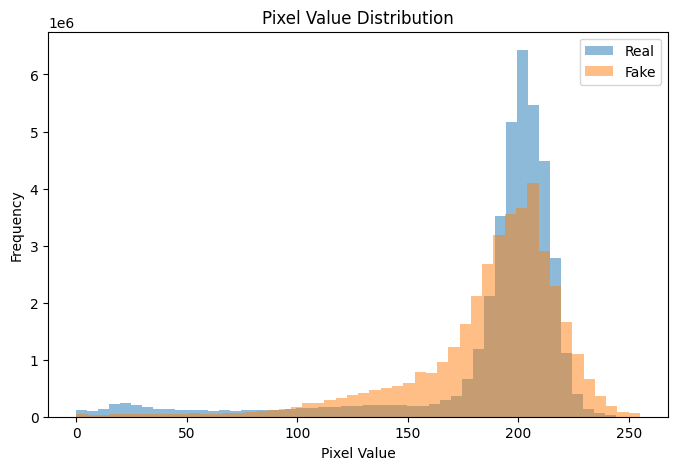

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(real_pixels, bins=50, alpha=0.5, label="Real")
plt.hist(fake_pixels, bins=50, alpha=0.5, label="Fake")

plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.title("Pixel Value Distribution")
plt.legend()

plt.show()

In [ ]:
from skimage.feature import hog
import cv2
import numpy as np

def extract_hog(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    features = hog(
        img,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

    return features

real_hog = np.array([extract_hog(path) for path in real_files])
fake_hog = np.array([extract_hog(path) for path in fake_files])

print("Real HOG shape:", real_hog.shape)
print("Fake HOG shape:", fake_hog.shape)

Real HOG shape: (600, 34596)
Fake HOG shape: (600, 34596)


In [ ]:
X_hog = np.vstack([real_hog, fake_hog])

y_hog = np.array([0] * len(real_hog) + [1] * len(fake_hog))

print("X shape:", X_hog.shape)
print("y shape:", y_hog.shape)
print("Real labels:", np.sum(y_hog == 0))
print("Fake labels:", np.sum(y_hog == 1))

X shape: (1200, 34596)
y shape: (1200,)
Real labels: 600
Fake labels: 600


In [ ]:
from skimage.feature import local_binary_pattern
import cv2
import numpy as np

def extract_lbp(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    radius = 1
    points = 8 * radius

    lbp = local_binary_pattern(img, points, radius, method="uniform")

    hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, points + 3),
        range=(0, points + 2)
    )

    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-7)

    return hist

real_lbp = np.array([extract_lbp(path) for path in real_files])
fake_lbp = np.array([extract_lbp(path) for path in fake_files])

print("Real LBP shape:", real_lbp.shape)
print("Fake LBP shape:", fake_lbp.shape)

Real LBP shape: (600, 10)
Fake LBP shape: (600, 10)


In [ ]:
X_lbp = np.vstack([real_lbp, fake_lbp])

y_lbp = np.array([0] * len(real_lbp) + [1] * len(fake_lbp))

print("X shape:", X_lbp.shape)
print("y shape:", y_lbp.shape)
print("Real labels:", np.sum(y_lbp == 0))
print("Fake labels:", np.sum(y_lbp == 1))

X shape: (1200, 10)
y shape: (1200,)
Real labels: 600
Fake labels: 600


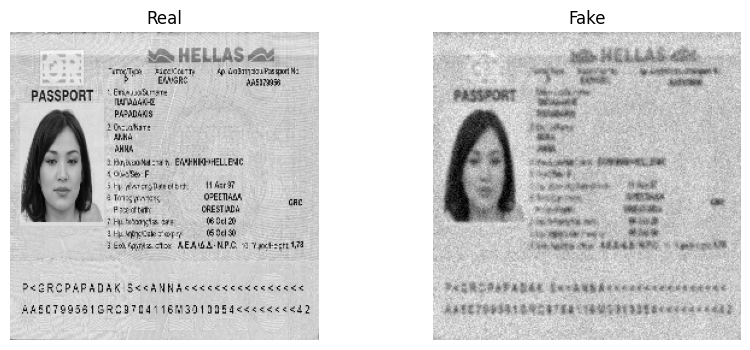

In [ ]:
import matplotlib.pyplot as plt

real_img = cv2.imread(real_files[0], cv2.IMREAD_GRAYSCALE)
fake_img = cv2.imread(fake_files[0], cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(real_img, cmap="gray")
plt.title("Real")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(fake_img, cmap="gray")
plt.title("Fake")
plt.axis("off")

plt.show()

In [ ]:
import cv2
import os
import glob
import numpy as np

input_dir = "/content/data/processed/positive"
output_dir = "/content/data/processed/fake"

os.makedirs(output_dir, exist_ok=True)

image_files = sorted(glob.glob(os.path.join(input_dir, "*.png")))

for i, path in enumerate(image_files[:600]):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        continue

    # Add Gaussian blur
    blurred = cv2.GaussianBlur(img, (5, 5), 0)

    # Add Gaussian noise
    noise = np.random.normal(0, 15, blurred.shape)
    fake = blurred.astype(np.float32) + noise

    # Keep pixel values between 0 and 255
    fake = np.clip(fake, 0, 255).astype(np.uint8)

    output_path = os.path.join(output_dir, f"{i:04d}.png")
    cv2.imwrite(output_path, fake)

print("Done!")
print("Fake images created:", len(glob.glob(os.path.join(output_dir, "*.png"))))
print("Saved to:", output_dir)

## Step 5: Preprocess — grayscale + resize

In [ ]:
TARGET_SIZE = (256, 256)  # revisit this after Task #5 EDA shows typical image dimensions

def preprocess_image(path, target_size=TARGET_SIZE):
    img = cv2.imread(path)
    if img is None:
        print(f"Warning: could not read {path}")
        return None
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    resized = cv2.resize(gray, target_size, interpolation=cv2.INTER_AREA)
    return resized

def process_list(paths, label):
    imgs, labels = [], []
    for path in paths:
        img = preprocess_image(path)
        if img is not None:
            imgs.append(img)
            labels.append(label)
    return imgs, labels

fake_paths = glob.glob(os.path.join(fake_dir, "*"))

real_imgs, real_labels = process_list(real_sample, label=0)   # 0 = real
fake_imgs, fake_labels = process_list(fake_paths, label=1)     # 1 = fake

all_imgs = np.array(real_imgs + fake_imgs)
all_labels = np.array(real_labels + fake_labels)

print(f"Processed {len(all_imgs)} images total")
print(f"Real: {len(real_imgs)}, Fake: {len(fake_imgs)}")
print(f"Array shape: {all_imgs.shape}")

## Step 6: Sanity check — view a few processed images

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
sample_indices = [0, 1, len(real_imgs), len(real_imgs) + 1]  # 2 real, 2 fake
titles = ['Real', 'Real', 'Fake', 'Fake']

for ax, idx, title in zip(axes, sample_indices, titles):
    ax.imshow(all_imgs[idx], cmap='gray')
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()

## Step 7: Save processed data


In [ ]:
os.makedirs("/content/data/processed", exist_ok=True)
np.save("/content/data/processed/images.npy", all_imgs)
np.save("/content/data/processed/labels.npy", all_labels)
print("Saved to /content/data/processed/")